# Chapitre 12 - Cours 2 : dégrouper la base de données

Le cours 1 a montré qu'une organisation qui dérive ses données d'un journal fait, à
grande échelle, ce qu'une base de données fait en interne quand elle tient ses index à
jour. Ce notebook prend l'analogie au sérieux : que se passe-t-il si l'on **sépare les
composants** d'une base (journal, index, vues matérialisées, code applicatif) et qu'on
les recompose avec des flux ? Il couvre les sections *Unbundling Databases* (*Composing
Data Storage Technologies*, y compris *What's missing?*) et *Designing Applications
Around Dataflow*.

**Plan.**

1. Bases de données, Unix et dégroupage.
2. Créer un index, c'est dériver une vue.
3. La méta-base de données de toute l'organisation.
4. Faire fonctionner le dégroupage : le couplage lâche.
5. Dégroupé ou intégré ?
6. Le code applicatif comme fonction de dérivation : le modèle du tableur.
7. Séparer le code et l'état, et s'abonner aux changements.
8. Processeurs de flux et services.

In [1]:
import math
import random
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Bases de données, Unix et dégroupage (section *Unbundling Databases*)

Vu de haut, une base de données, un moteur de traitement par lots ou de flux et un
système d'exploitation font la même chose : ils **stockent** des données et permettent
de les **traiter et interroger**. La base range des enregistrements d'un modèle de
données (lignes, documents, sommets), le système de fichiers range des fichiers ; ce
sont deux systèmes de gestion de l'information (avec de grosses différences pratiques :
dix millions de petits fichiers dans un répertoire gênent la plupart des systèmes de
fichiers, dix millions de petites lignes dans une table sont banals).

Les deux traditions ont pourtant des philosophies opposées, nées au même moment (Unix
et le modèle relationnel datent tous deux du début des années 1970) :

| | Unix | bases relationnelles |
|---|---|---|
| abstraction | mince couche logique au-dessus du matériel | haut niveau : cache structures disque, concurrence, reprise |
| briques | fichiers = suites d'octets, tubes (pipes) | SQL, transactions |
| « simple » parce que... | peu de choses entre vous et le matériel | une requête déclarative courte mobilise optimiseur, index, jointures, réplication |
| composition | petits outils assemblés par le shell | un seul système intégré |

Le mouvement NoSQL peut se lire comme l'application de l'esprit Unix (abstractions de
bas niveau) au stockage transactionnel distribué. Le livre tente de **réconcilier** les
deux : garder les abstractions de haut niveau des bases, mais les construire en
composant des briques spécialisées, comme le shell compose des outils.

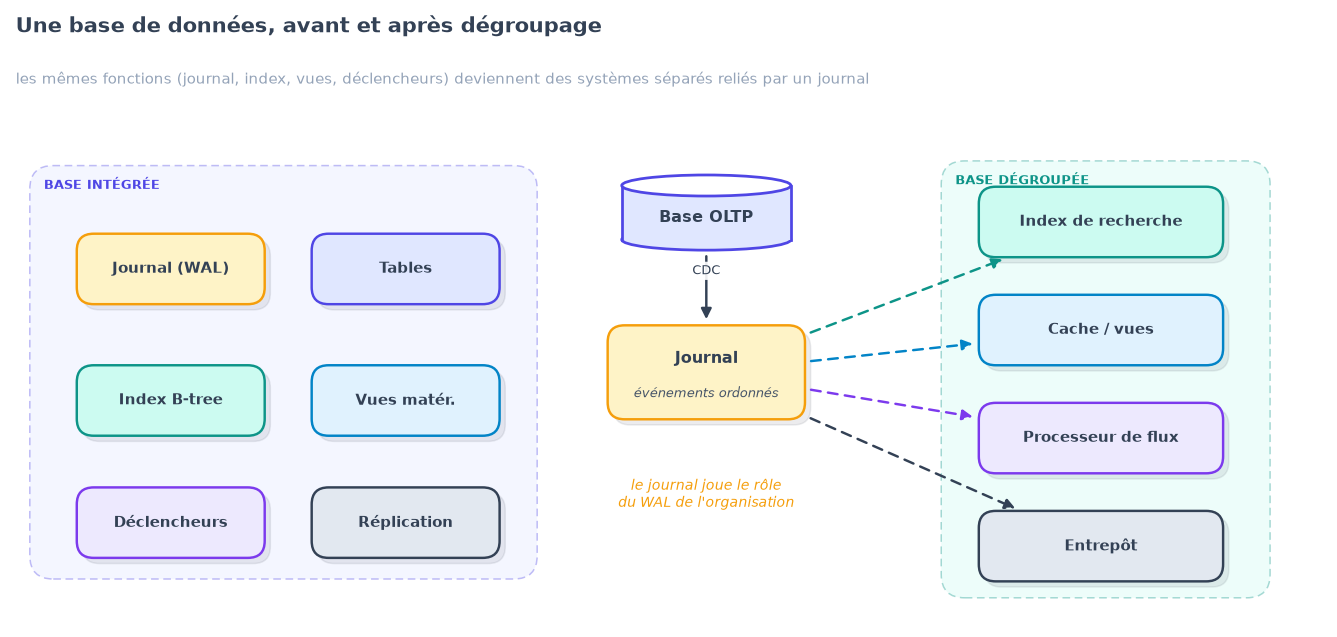

In [2]:
d = Diagram(14, 5.6, title="Une base de données, avant et après dégroupage",
            subtitle="les mêmes fonctions (journal, index, vues, déclencheurs) deviennent des systèmes séparés reliés par un journal")
d.group(0.2, 0.5, 5.6, 4.9, "base intégrée", color=INDIGO)
inner = [("wal", "Journal (WAL)", 1.7, 3.8, AMBER), ("tbl", "Tables", 4.2, 3.8, INDIGO),
         ("ix", "Index B-tree", 1.7, 2.4, TEAL), ("mv", "Vues matér.", 4.2, 2.4, SKY),
         ("trg", "Déclencheurs", 1.7, 1.1, VIOLET), ("rep", "Réplication", 4.2, 1.1, SLATE)]
for name, txt, x, y, c in inner:
    d.box(name, x, y, txt, color=c, w=2.0, h=0.75, fontsize=9.5)
d.box("log", 7.4, 2.7, "Journal", sub="événements ordonnés", color=AMBER, w=2.1, h=1.0)
outer = [("es", "Index de recherche", 11.6, 4.3, TEAL), ("cache", "Cache / vues", 11.6, 3.15, SKY),
         ("sp", "Processeur de flux", 11.6, 2.0, VIOLET), ("dwh", "Entrepôt", 11.6, 0.85, SLATE)]
d.group(9.9, 0.3, 13.4, 4.95, "base dégroupée", color=TEAL)
for name, txt, x, y, c in outer:
    d.box(name, x, y, txt, color=c, w=2.6, h=0.75, fontsize=9.5)
    d.arrow("log", name, style="dashed", color=c)
d.box("db", 7.4, 4.4, "Base OLTP", color=INDIGO, kind="db", w=1.8, h=0.8)
d.arrow("db", "log", "CDC")
d.note(7.4, 1.4, "le journal joue le rôle\ndu WAL de l'organisation", color=AMBER)
d.show()

> **À retenir.** Unix compose de petits outils de bas niveau ; les bases offrent une
> abstraction de haut niveau intégrée. Dégrouper la base, c'est chercher le meilleur des
> deux : des fonctions de base de données (index, vues, déclencheurs) fournies par des
> systèmes séparés, assemblés par un journal.

## 2. Créer un index, c'est dériver une vue (sections *Composing Data Storage Technologies* et *Creating an index*)

Une base offre index secondaires, vues matérialisées (des caches de résultats de
requêtes), journaux de réplication, parfois des index plein texte. Les chapitres
10 et 11 ont construit les mêmes choses **à l'extérieur** de la base :
index de recherche, maintenance de vues matérialisées, réplication vers des systèmes
dérivés par CDC. Le parallèle est frappant quand on regarde ce que fait `CREATE INDEX`
sans verrouiller la table :

1. parcourir un **instantané cohérent** de la table, extraire et trier les valeurs indexées,
   écrire l'index ;
2. appliquer le **retard** : toutes les écritures faites depuis l'instantané ;
3. ensuite, tenir l'index à jour à chaque écriture.

C'est exactement la mise en place d'un nouveau suiveur (chapitre 5) ou
l'amorçage d'un CDC par un instantané initial (chapitre 11). Implémentons-le
(`dfl.IndexBuilder`) sur une table de commandes indexée par statut, pendant que les
écritures continuent.

In [3]:
rng = random.Random(3)
statuts = ["créée", "payée", "expédiée", "livrée", "annulée"]
changes = []
for i in range(6000):
    k = rng.randrange(800)
    changes.append(("del", k, None) if rng.random() < 0.05 else ("put", k, rng.choice(statuts)))
snap_at = 3000                                           # l'instantané est pris après 3 000 changements

builder = dfl.IndexBuilder()
builder.load_snapshot(dfl.replay_table(changes, snap_at), snap_at)
after_snapshot = builder.as_dict()
builder.catch_up(changes)                                 # rattrapage du retard, puis suivi
truth = dfl.index_from_table(dfl.replay_table(changes))
def n_wrong(idx):
    keys = set(idx) | set(truth)
    return sum(len(set(idx.get(v, [])) ^ set(truth.get(v, []))) for v in keys)
pd.DataFrame({"étape": ["instantané seul", "instantané + rattrapage"],
              "entrées d'index fausses": [n_wrong(after_snapshot), n_wrong(builder.as_dict())],
              "changements appliqués après l'instantané": [0, builder.applied]})

,étape,entrées d'index fausses,changements appliqués après l'instantané
0,instantané seul,1191,0
1,instantané + rattrapage,0,3000


Sans l'étape 2, l'index construit sur l'instantané est faux pour plusieurs centaines
d'entrées : toutes les commandes modifiées depuis. Avec le rattrapage, il coïncide
exactement avec un index construit d'un coup sur l'état final. **Créer un index, c'est
retraiter les données existantes pour en dériver une nouvelle vue.** L'état de départ
est un instantané plutôt qu'un journal complet, mais les deux sont proches (un
instantané est la compaction d'un journal).

**Combien de temps dure la construction ?** Si l'on parcourt l'instantané à $S$ lignes/s
pendant que les écritures arrivent à $r$/s, puis qu'on rattrape à $c$/s ($c > r$), le
retard accumulé pendant le parcours de $N$ lignes vaut $rN/S$ et se résorbe en
$\frac{rN/S}{c - r}$ secondes.

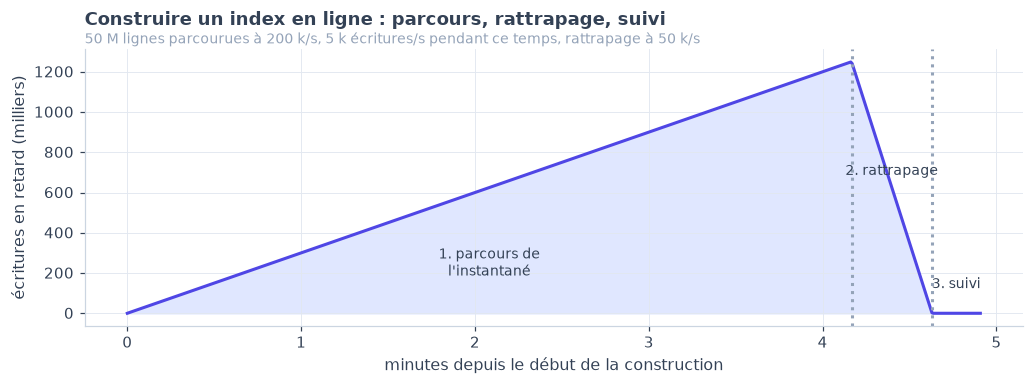

parcours : 4.2 min ; retard accumulé : 1.25 M écritures ; rattrapage : 28 s


In [4]:
N, S, r_, c_ = 50e6, 200e3, 5e3, 50e3
t_scan = N / S
backlog = r_ * t_scan
t_catch = backlog / (c_ - r_)
t = np.linspace(0, t_scan + t_catch * 1.6, 600)
lag = np.where(t <= t_scan, r_ * t, np.maximum(0, backlog - (c_ - r_) * (t - t_scan)))
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.fill_between(t / 60, lag / 1e3, color=LIGHT[INDIGO]); ax.plot(t / 60, lag / 1e3, color=INDIGO)
ax.axvline(t_scan / 60, color=GRAY, ls=":"); ax.axvline((t_scan + t_catch) / 60, color=GRAY, ls=":")
ax.text(t_scan / 120, backlog / 1e3 * 0.15, "1. parcours de\nl'instantané", ha="center", fontsize=9, color=SLATE)
ax.text((t_scan + t_catch / 2) / 60, backlog / 1e3 * 0.55, "2. rattrapage", ha="center", fontsize=9, color=SLATE)
ax.text((t_scan + t_catch * 1.3) / 60, backlog / 1e3 * 0.1, "3. suivi", ha="center", fontsize=9, color=SLATE)
ax.set_xlabel("minutes depuis le début de la construction"); ax.set_ylabel("écritures en retard (milliers)")
ax.set_title("Construire un index en ligne : parcours, rattrapage, suivi")
subtitle(ax, "50 M lignes parcourues à 200 k/s, 5 k écritures/s pendant ce temps, rattrapage à 50 k/s")
plt.tight_layout(); plt.show()
print(f"parcours : {t_scan / 60:.1f} min ; retard accumulé : {backlog / 1e6:.2f} M écritures ; rattrapage : {t_catch:.0f} s")

Le parcours dure un peu plus de quatre minutes et accumule 1,25 million d'écritures en
retard, rattrapées en moins d'une demi-minute. Le même raisonnement dimensionne
l'amorçage d'un nouveau système dérivé par CDC : la marge $c - r$ entre la vitesse de
rattrapage et le débit d'écriture décide de tout (si $c \le r$, on ne rattrape jamais).

> **À retenir.** `CREATE INDEX` = instantané + rattrapage du journal + suivi : c'est la
> même mécanique que l'ajout d'un suiveur ou l'amorçage d'un CDC. Un index est une vue
> dérivée, et la base sait déjà dériver des vues ; le dégroupage applique cette
> mécanique à des systèmes séparés.

## 3. La méta-base de données de toute l'organisation (sections *The meta-database of everything*, *Federated databases* et *Unbundled databases*)

Sous cet angle, le flux de données d'une organisation entière ressemble à **une seule
base de données géante**. Chaque traitement par lots, de flux ou ETL qui transporte des
données d'un endroit et d'une forme vers d'autres joue le rôle du sous-système qui tient
index et vues à jour :

| dans une base intégrée | dans l'organisation dégroupée |
|---|---|
| journal de transactions (WAL) | journal d'événements ou flux CDC |
| types d'index (B-tree, hachage, spatial...) | systèmes dérivés (moteur de recherche, cache, entrepôt...) |
| déclencheurs, procédures stockées, maintenance des vues | traitements de flux et par lots |
| un seul produit, une seule équipe | des logiciels différents, sur des machines différentes, gérés par des équipes différentes |

Si aucun modèle de données ne convient à tous les accès, deux voies permettent de
recomposer un tout cohérent :

- **unifier les lectures** : une base **fédérée** (ou polystore) offre une interface de
  requête unique au-dessus de moteurs variés (les foreign data wrappers de PostgreSQL relèvent de ce modèle) ; c'est la tradition relationnelle :
  un langage de haut niveau, une implémentation compliquée ;
- **unifier les écritures** : une base **dégroupée** garantit que chaque changement
  arrive à tous les bons endroits malgré les pannes (CDC, journaux) ; c'est la tradition
  Unix : de petits outils qui font une chose bien, une interface uniforme de bas niveau
  (les tubes), un langage de composition (le shell).

Voici une requête fédérée minimale : les produits sont dans SQLite (système de
référence), les descriptions dans un index inversé, les stocks dans un dictionnaire
façon cache. La « base fédérée » répartit la requête entre les trois et joint les
résultats.

In [5]:
conn = sqlite3.connect(":memory:")
conn.execute("CREATE TABLE produits (id INTEGER PRIMARY KEY, nom TEXT, prix REAL)")
catalogue = [(1, "stylo plume", 35.0, "stylo plume acier encre bleue"),
             (2, "carnet ligné", 9.5, "carnet papier ligné couverture rigide"),
             (3, "stylo bille", 2.0, "stylo bille encre bleue rétractable"),
             (4, "encre noire", 7.0, "flacon encre noire stylo plume"),
             (5, "carnet pointillé", 12.0, "carnet papier pointillé couverture souple")]
conn.executemany("INSERT INTO produits VALUES (?, ?, ?)", [c[:3] for c in catalogue])
vocab = {}
index = dfl.InvertedIndex()
for pid, *_, desc in catalogue:
    index.add(pid, [vocab.setdefault(w, len(vocab)) for w in desc.split()])
stock = {1: 4, 2: 0, 3: 120, 4: 15, 5: 7}                  # « cache » des stocks

def requete_federee(mots, prix_max):
    ids = index.search_and([vocab[w] for w in mots])                     # moteur 1 : recherche
    rows = conn.execute(f"SELECT id, nom, prix FROM produits WHERE prix <= ? AND id IN "
                        f"({','.join('?' * len(ids))})", (prix_max, *ids)).fetchall()  # moteur 2 : SQL
    return pd.DataFrame([(i, n, p, stock[i]) for i, n, p in rows],                   # moteur 3 : stock
                        columns=["id", "nom", "prix", "stock"])

requete_federee(["encre", "bleue"], prix_max=50)

,id,nom,prix,stock
0,1,stylo plume,35.0,4
1,3,stylo bille,2.0,120


La lecture fédérée est un problème de **traduction** entre modèles de données : il
faut réfléchir, mais c'est gérable. Le vrai problème est l'**écriture** : quand un
produit change, qui garantit que SQLite, l'index et le cache sont tous mis à jour, dans
le même ordre, malgré les pannes ? C'est le rôle du dégroupage, auquel le livre consacre
la suite.

> **À retenir.** L'organisation entière peut se voir comme une méta-base : les systèmes
> dérivés sont ses index, les traitements de flux ses déclencheurs. La fédération unifie
> les lectures (facile) ; le dégroupage unifie les écritures (difficile, et essentiel).